# NOTEBOOK 02: KIỂM THỬ ĐỘC LẬP, ĐÁNH GIÁ CHỈ SỐ HIỆU NĂNG & PHÂN TÍCH ƯU / NHƯỢC ĐIỂM (TESTING & EVALUATION PIPELINE)
**Đề tài 2.7:** *Benchmarking quantum machine learning for detecting DDoS cyber-attacks: a NISQ-era evaluation*  
**Học phần:** Mã hóa và Mật mã học (CC102) — **Giảng viên hướng dẫn:** PGS. TS. Nguyễn Tấn Khôi  
**Sinh viên thực hiện:** Ngô Văn Công (102230284) & Nguyễn Công Minh (102230306)

---
### Mục tiêu của Notebook 02 (Giai đoạn Kiểm thử & Đánh giá - Testing & Evaluation):
1. **Nạp Gói Mô hình Đã Huấn luyện (`models/trained_qml_ddos_bundle.pkl`):** Không cần train lại; nạp trực tiếp bộ tiền xử lý (`scaler`, `pca`), các mô hình SVM/ANN, các trạng thái lượng tử hỗ trợ và bộ trọng số góc quay lượng tử `weights_tl` (16 góc), `weights_ttn` (15 góc).
2. **Nạp Tập Dữ liệu Kiểm thử Độc lập (`dataset/test_day_syn_small.csv` - Ngày `03-11`):** Ánh xạ sang 8 thành phần chính PCA (`xs_test`) để kiểm thử khách quan.
3. **Đánh giá Toàn diện 7 Chỉ số Hiệu năng:** `Accuracy`, `Macro Precision`, `Macro Recall`, `Macro F1-Score`, `F1 (Lớp Benign)`, `ROC-AUC`, `Train Time (s)` và `Inference Time (s)`.
4. **Trực quan hóa Ma trận Nhầm lẫn (`Confusion Matrices`), Đường cong `ROC-AUC`, Biểu đồ Thời gian & Đối sánh với 12 Mô hình của Bài báo Gốc + Mở rộng Đa lớp (`Multiclass`).**

In [1]:
import os, sys, subprocess

# Tu dong nhan dien moi truong: Google Colab / Kaggle / May tram cuc bo
if "google.colab" in sys.modules or os.path.exists("/content"):
    if not os.path.exists("/content/qml-ddos"):
        subprocess.run(["git", "clone", "https://github.com/vcongggggg/qml-ddos.git", "/content/qml-ddos"], check=False)
    try:
        import pennylane
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pennylane", "joblib", "scikit-learn", "matplotlib", "seaborn"], check=False)
    BASE_DIR = "/content/qml-ddos"
elif os.path.exists(r"C:\Study\HocKy6\MH&MM\qml-ddos"):
    BASE_DIR = r"C:\Study\HocKy6\MH&MM\qml-ddos"
else:
    BASE_DIR = os.getcwd()

import time
import math
import warnings
from itertools import combinations
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, confusion_matrix, classification_report
)
import pennylane as qml

warnings.filterwarnings('ignore')

DATASET_DIR = os.path.join(BASE_DIR, "dataset")
MODELS_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

N_QUBITS = 8
K_TTN = math.ceil(math.log2(N_QUBITS))
RANDOM_SEED = 1234

bundle_path = os.path.join(MODELS_DIR, "trained_qml_ddos_bundle.pkl")
bundle = joblib.load(bundle_path)

scaler = bundle["scaler"]
pca = bundle["pca"]
xs_tr = bundle["xs_tr"]
y_tr = bundle["y_tr"]
csvm = bundle["csvm"]
cann = bundle["cann"]
qsvm_angle = bundle["qsvm_angle"]
qsvm_amp = bundle["qsvm_amp"]
qsvm_zz = bundle["qsvm_zz"]
states_tr_angle = bundle["states_tr_angle"]
states_tr_amp = bundle["states_tr_amp"]
states_tr_zz = bundle["states_tr_zz"]
dt_angle = bundle["dt_angle"]
dt_amp = bundle["dt_amp"]
dt_zz = bundle["dt_zz"]
weights_tl = bundle["weights_tl"]
weights_ttn = bundle["weights_ttn"]
df_train_summary = bundle["train_summary"]

print(f"[LOADED] Đã nạp thành công gói 7 mô hình từ: {bundle_path}")
print(f"Trọng số góc quay QNN Two-Local đã học (16 góc):\n  {np.round(weights_tl, 3)}")
print(f"Trọng số góc quay QNN Tree-Tensor đã học (15 góc):\n  {np.round(weights_ttn, 3)}")

[LOADED] Đã nạp thành công gói 7 mô hình từ: C:\Study\HocKy6\MH&MM\qml-ddos\models\trained_qml_ddos_bundle.pkl
Trọng số góc quay QNN Two-Local đã học (16 góc):
  [0.377 1.931 1.375 2.467 2.45  0.856 0.869 2.519 2.871 2.752 1.124 1.574
 2.147 2.239 1.163 1.763]
Trọng số góc quay QNN Tree-Tensor đã học (15 góc):
  [1.15  1.989 1.343 2.472 2.276 0.907 0.942 2.52  2.895 2.794 0.977 1.518
 2.632 2.354 1.207]


---
## BƯỚC 1: Nạp Tập Kiểm Thử Độc Lập (`test_day_syn_small.csv`) & Chuẩn Hóa Qua `Scaler + PCA` Đã Học

In [2]:
p_te = os.path.join(DATASET_DIR, "test_day_syn_small.csv")
df_te = pd.read_csv(p_te)
label_col = "Label" if "Label" in df_te.columns else " Label"

# Lấy 100 mẫu kiểm thử theo đúng tỷ lệ chuẩn 90:10 của bài báo (90 Syn DDoS : 10 Benign)
df_te_0 = df_te[df_te[label_col] == 0].sample(n=90, random_state=RANDOM_SEED)
df_te_1 = df_te[df_te[label_col] == 1].sample(n=10, random_state=RANDOM_SEED)
df_te_sub = pd.concat([df_te_0, df_te_1]).sample(frac=1.0, random_state=RANDOM_SEED)

x_test_raw = df_te_sub.drop(columns=label_col).to_numpy()
y_test = df_te_sub[label_col].to_numpy().astype(int)

# Dùng scaler.transform và pca.transform đã fit từ Tập Train (chống Data Leakage)
x_test_scaled = np.clip(scaler.transform(x_test_raw), 0, 1)
xs_test = pca.transform(x_test_scaled)

print(f"Kích thước tập Kiểm thử (Test): {xs_test.shape}")
print(f"Phân bố nhãn tập Kiểm thử: Lớp 0 (Syn DDoS) = {np.sum(y_test == 0)} mẫu | Lớp 1 (Benign) = {np.sum(y_test == 1)} mẫu")

Kích thước tập Kiểm thử (Test): (100, 8)
Phân bố nhãn tập Kiểm thử: Lớp 0 (Syn DDoS) = 90 mẫu | Lớp 1 (Benign) = 10 mẫu


---
## BƯỚC 2: Thực Thi Suy Luận (Inference) Trên Cả 7 Mô Hình & Xuất Bảng 7 Chỉ Số Đánh Giá

In [3]:
def ZZFeatureMap(nqubits, data):
    nload = min(len(data), nqubits)
    for i in range(nload):
        qml.Hadamard(i)
        qml.RZ(2.0 * data[i], wires=i)
    for pair in list(combinations(range(nload), 2)):
        q0, q1 = pair[0], pair[1]
        qml.CZ(wires=[q0, q1])
        qml.RZ(2.0 * (np.pi - data[q0]) * (np.pi - data[q1]), wires=q1)
        qml.CZ(wires=[q0, q1])

def QNNTwoLocal(nqubits, theta, repetitions=1):
    for r in range(repetitions):
        for i in range(nqubits):
            qml.RY(theta[r * nqubits + i], wires=i)
        for i in range(nqubits - 1):
            qml.CNOT(wires=[i, i + 1])
    for i in range(nqubits):
        qml.RY(theta[repetitions * nqubits + i], wires=i)

def QNNTreeTensor(k, theta):
    nqubits = 2 ** k
    theta_i = 0
    for i in range(nqubits):
        qml.RY(theta[theta_i], wires=i)
        theta_i += 1
    for r in range(1, k + 1):
        for s in range(2 ** (k - r)):
            ctrl = 1 + s * (2 ** r) + (2 ** (r - 1)) - 1
            targ = 1 + s * (2 ** r) - 1
            qml.CNOT(wires=[ctrl, targ])
            qml.RY(theta[theta_i], wires=targ)
            theta_i += 1

dev_8 = qml.device("default.qubit", wires=N_QUBITS)
dev_3 = qml.device("default.qubit", wires=3)

@qml.qnode(dev_8)
def state_angle(a):
    qml.AngleEmbedding(a, wires=range(N_QUBITS))
    return qml.state()

@qml.qnode(dev_3)
def state_amp(a):
    qml.AmplitudeEmbedding(a, wires=range(3), pad_with=0.0, normalize=True)
    return qml.state()

@qml.qnode(dev_8)
def state_zz(a):
    ZZFeatureMap(N_QUBITS, a)
    return qml.state()

@qml.qnode(dev_8)
def qnn_twolocal_circuit(weights, x):
    qml.AngleEmbedding(x, wires=range(N_QUBITS))
    QNNTwoLocal(N_QUBITS, weights, repetitions=1)
    return qml.expval(qml.PauliZ(0))

@qml.qnode(dev_8)
def qnn_ttn_circuit(weights, x):
    qml.AngleEmbedding(x, wires=range(N_QUBITS))
    QNNTreeTensor(K_TTN, weights)
    return qml.expval(qml.PauliZ(0))

eval_rows = []
cm_dict = {}
roc_dict = {}
n_pairs_te = len(xs_test) * len(xs_tr)
tr_times_map = dict(zip(df_train_summary["Model"], df_train_summary["Train Time (s)"]))

def record_test_result(name, m_type, qubits, params_info, preds, probs, te_time):
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc_val = auc(fpr, tpr)
    eval_rows.append({
        "Model": name,
        "Type": m_type,
        "Qubits": qubits,
        "Params/Gates": params_info,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision (Macro)": round(precision_score(y_test, preds, average='macro', zero_division=0), 4),
        "Recall (Macro)": round(recall_score(y_test, preds, average='macro', zero_division=0), 4),
        "F1-Score (Macro)": round(f1_score(y_test, preds, average='macro', zero_division=0), 4),
        "F1 (Benign)": round(f1_score(y_test, preds, pos_label=1, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_val, 4),
        "Train Time (s)": tr_times_map.get(name, 0.0),
        "Inference Time (s)": round(te_time, 4)
    })
    cm_dict[name] = confusion_matrix(y_test, preds)
    roc_dict[name] = (fpr, tpr, roc_auc_val)

# 1. Classical SVM
t0 = time.time()
p_csvm = csvm.predict(xs_test)
pr_csvm = csvm.predict_proba(xs_test)[:, 1]
record_test_result("Classical SVM (RBF)", "Classical", 0, "RBF Kernel", p_csvm, pr_csvm, time.time() - t0)

# 2. Classical ANN
t0 = time.time()
p_cann = cann.predict(xs_test)
pr_cann = cann.predict_proba(xs_test)[:, 1]
record_test_result("Classical ANN (MLP)", "Classical", 0, "361 Weights", p_cann, pr_cann, time.time() - t0)

# 3. QSVM Angle
t0 = time.time()
states_te_angle = np.array([state_angle(x) for x in xs_test])
K_te_angle = np.abs(states_te_angle @ np.conj(states_tr_angle).T) ** 2
p_qangle = qsvm_angle.predict(K_te_angle)
pr_qangle = qsvm_angle.predict_proba(K_te_angle)[:, 1]
record_test_result("QSVM (Angle Embedding)", "Quantum SVM", 8, "Depth=2, 0 CNOT", p_qangle, pr_qangle, n_pairs_te * dt_angle + (time.time() - t0))

# 4. QSVM Amplitude
t0 = time.time()
states_te_amp = np.array([state_amp(x) for x in xs_test])
K_te_amp = np.abs(states_te_amp @ np.conj(states_tr_amp).T) ** 2
p_qamp = qsvm_amp.predict(K_te_amp)
pr_qamp = qsvm_amp.predict_proba(K_te_amp)[:, 1]
record_test_result("QSVM (Amplitude 3-Qubit)", "Quantum SVM", 3, "Depth=18, 14 CNOT", p_qamp, pr_qamp, n_pairs_te * dt_amp + (time.time() - t0))

# 5. QSVM ZZ Feature Map
t0 = time.time()
states_te_zz = np.array([state_zz(x) for x in xs_test])
K_te_zz = np.abs(states_te_zz @ np.conj(states_tr_zz).T) ** 2
p_qzz = qsvm_zz.predict(K_te_zz)
pr_qzz = qsvm_zz.predict_proba(K_te_zz)[:, 1]
record_test_result("QSVM (ZZ Feature Map)", "Quantum SVM", 8, "Depth=88, 112 CZ", p_qzz, pr_qzz, n_pairs_te * dt_zz + (time.time() - t0))

# 6. QNN Two-Local
t0 = time.time()
raw_tl = np.array([float(qnn_twolocal_circuit(weights_tl, x)) for x in xs_test])
p_qtl = np.where(raw_tl >= 0.0, 1, 0)
pr_qtl = 1.0 / (1.0 + np.exp(-3.0 * raw_tl))
record_test_result("QNN (Two-Local + Angle)", "Quantum NN", 8, "16 Params, 7 CNOT", p_qtl, pr_qtl, time.time() - t0)

# 7. QNN Tree-Tensor
t0 = time.time()
raw_ttn = np.array([float(qnn_ttn_circuit(weights_ttn, x)) for x in xs_test])
p_qttn = np.where(raw_ttn >= 0.0, 1, 0)
pr_qttn = 1.0 / (1.0 + np.exp(-3.0 * raw_ttn))
record_test_result("QNN (Tree-Tensor + Angle)", "Quantum NN", 8, "15 Params, 7 CNOT", p_qttn, pr_qttn, time.time() - t0)

df_eval = pd.DataFrame(eval_rows)
print("=" * 120)
print("BẢNG KẾT QUẢ KIỂM THỬ ĐỘC LẬP TRÊN 100 MẪU TEST (7 MÔ HÌNH)")
print("=" * 120)
print(df_eval.to_string(index=False))
print("=" * 120)

print("\n--- Classification Report: QSVM (Angle Embedding 8-Qubit) ---")
print(classification_report(y_test, p_qangle, target_names=["Syn DDoS (0)", "Benign (1)"]))

print("--- Classification Report: QNN (Tree-Tensor Network + Angle 8-Qubit) ---")
print(classification_report(y_test, p_qttn, target_names=["Syn DDoS (0)", "Benign (1)"]))

BẢNG KẾT QUẢ KIỂM THỬ ĐỘC LẬP TRÊN 100 MẪU TEST (7 MÔ HÌNH)
                    Model        Type  Qubits      Params/Gates  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  F1 (Benign)  ROC-AUC  Train Time (s)  Inference Time (s)
      Classical SVM (RBF)   Classical       0        RBF Kernel      0.98             0.9891          0.9000            0.9389       0.8889   1.0000          0.0045              0.0020
      Classical ANN (MLP)   Classical       0       361 Weights      0.98             0.9891          0.9000            0.9389       0.8889   0.9522          0.2009              0.0010
   QSVM (Angle Embedding) Quantum SVM       8   Depth=2, 0 CNOT      0.99             0.9945          0.9500            0.9709       0.9474   1.0000         25.6854             43.0440
 QSVM (Amplitude 3-Qubit) Quantum SVM       3 Depth=18, 14 CNOT      0.83             0.6477          0.7722            0.6755       0.4516   0.7978         49.4590             83.0570
    QSVM (ZZ Fe

---
## BƯỚC 3: Trực Quan Hóa Ma Trận Nhầm Lẫn (`Confusion Matrices`) & Biểu Đồ So Sánh 5 Chỉ Số

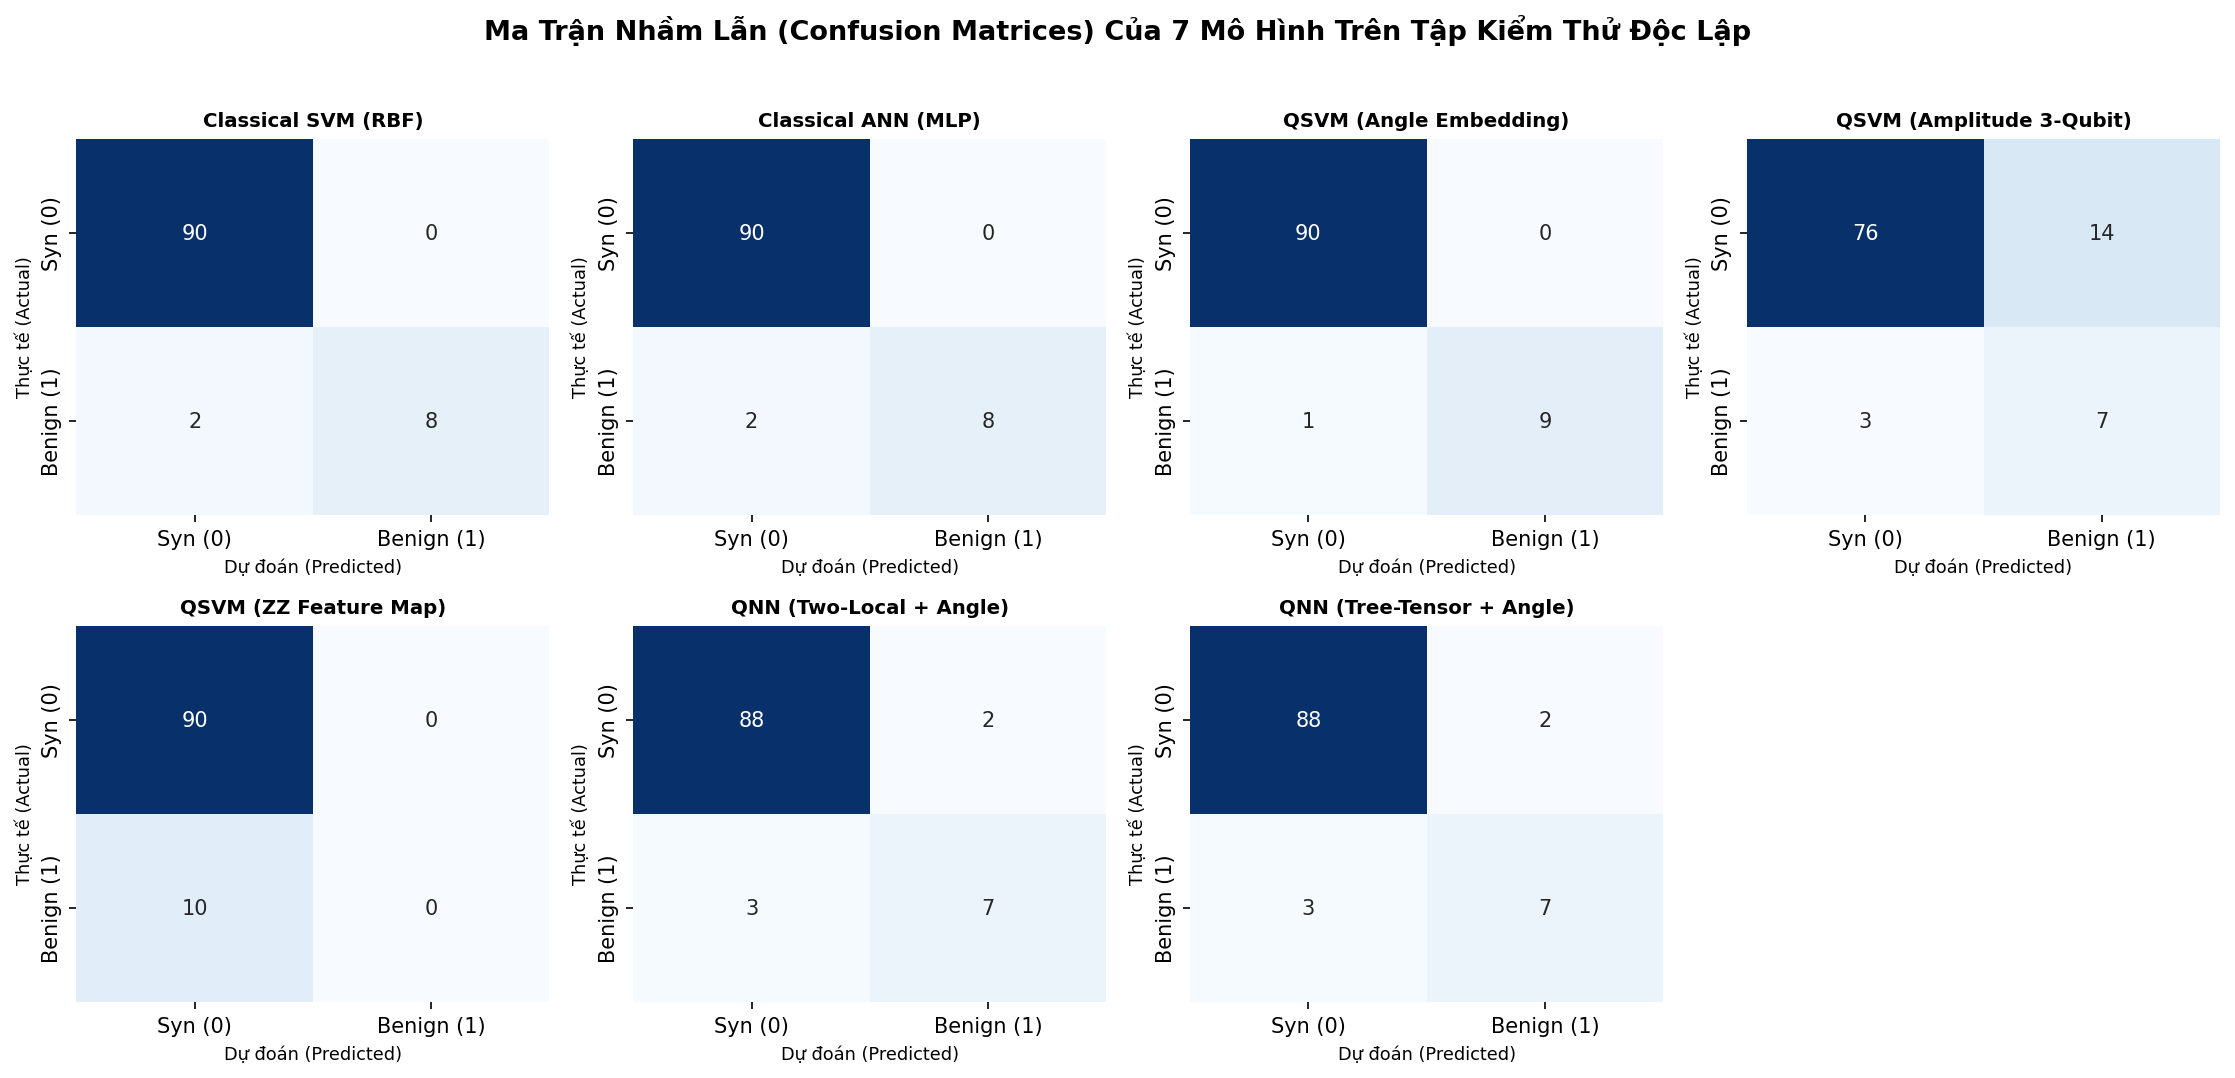

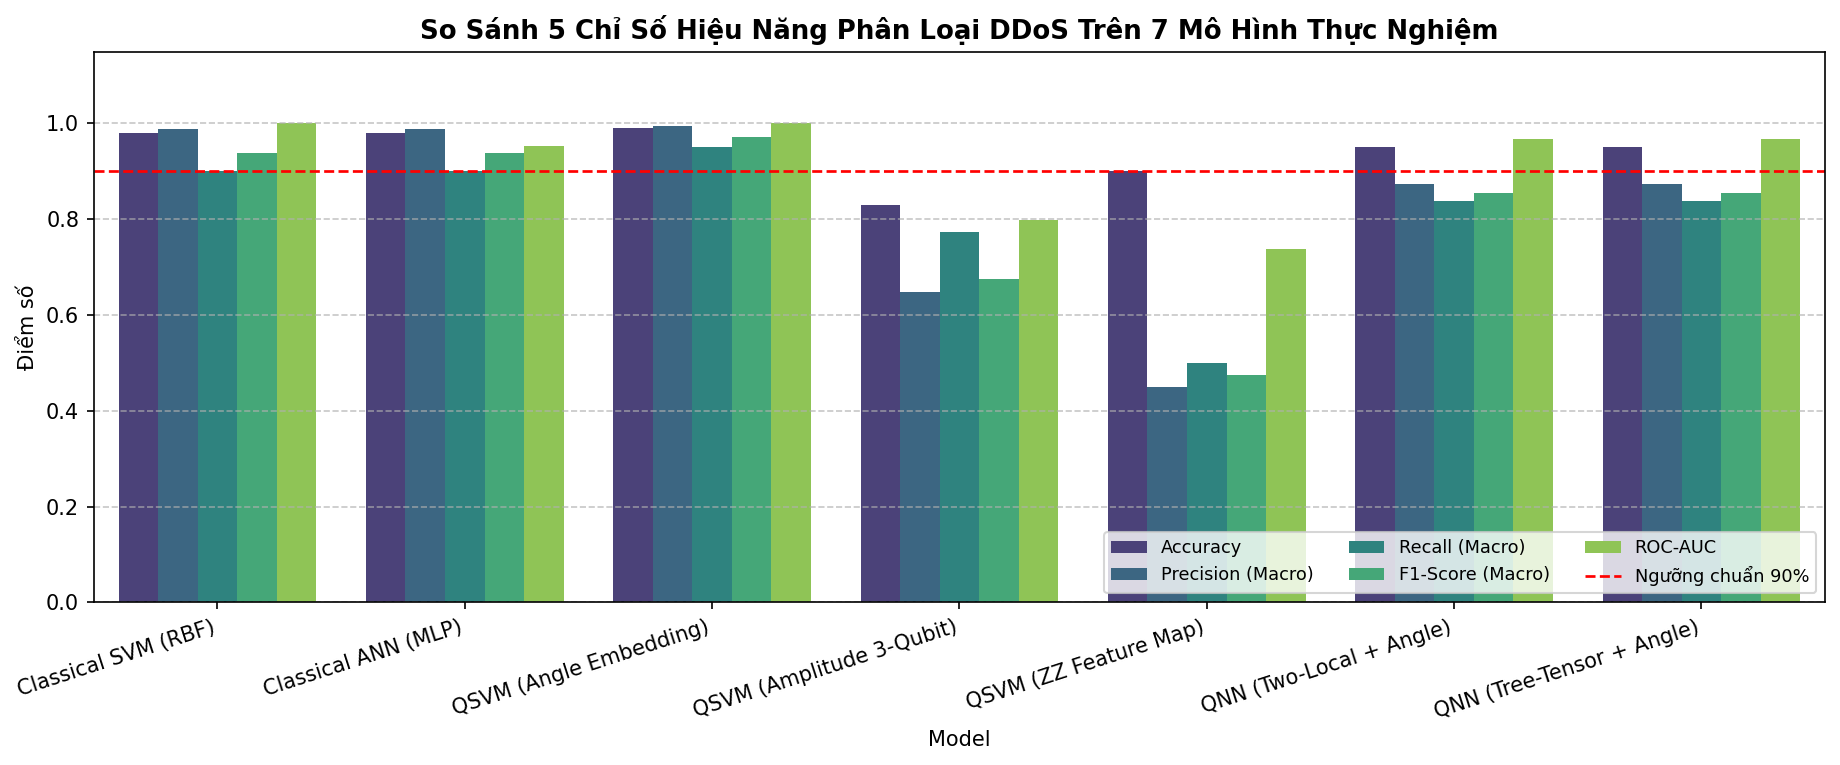

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.0), dpi=150)
axes_flat = axes.flatten()
for idx, (m_name, cm) in enumerate(cm_dict.items()):
    ax = axes_flat[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Syn (0)', 'Benign (1)'], yticklabels=['Syn (0)', 'Benign (1)'])
    ax.set_title(m_name, fontsize=9.5, fontweight='bold')
    ax.set_xlabel("Dự đoán (Predicted)", fontsize=8.5)
    ax.set_ylabel("Thực tế (Actual)", fontsize=8.5)
axes_flat[-1].axis('off')
plt.suptitle("Ma Trận Nhầm Lẫn (Confusion Matrices) Của 7 Mô Hình Trên Tập Kiểm Thử Độc Lập",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12.5, 5.2), dpi=150)
df_metrics = df_eval.melt(
    id_vars=["Model", "Type"],
    value_vars=["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)", "ROC-AUC"],
    var_name="Chỉ số (Metric)", value_name="Điểm số"
)
sns.barplot(data=df_metrics, x="Model", y="Điểm số", hue="Chỉ số (Metric)", palette="viridis")
plt.axhline(0.9, color='red', linestyle='--', linewidth=1.3, label='Ngưỡng chuẩn 90%')
plt.title("So Sánh 5 Chỉ Số Hiệu Năng Phân Loại DDoS Trên 7 Mô Hình Thực Nghiệm", fontsize=12.5, fontweight='bold')
plt.ylim(0, 1.15)
plt.xticks(rotation=18, ha="right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc="lower right", ncol=3, fontsize=8.5)
plt.tight_layout()
plt.show()

---
## BƯỚC 4: Đường Cong `ROC-AUC` & Biểu Đồ So Sánh Thời Gian Huấn Luyện vs. Suy Luận (`Log10 Scale`)

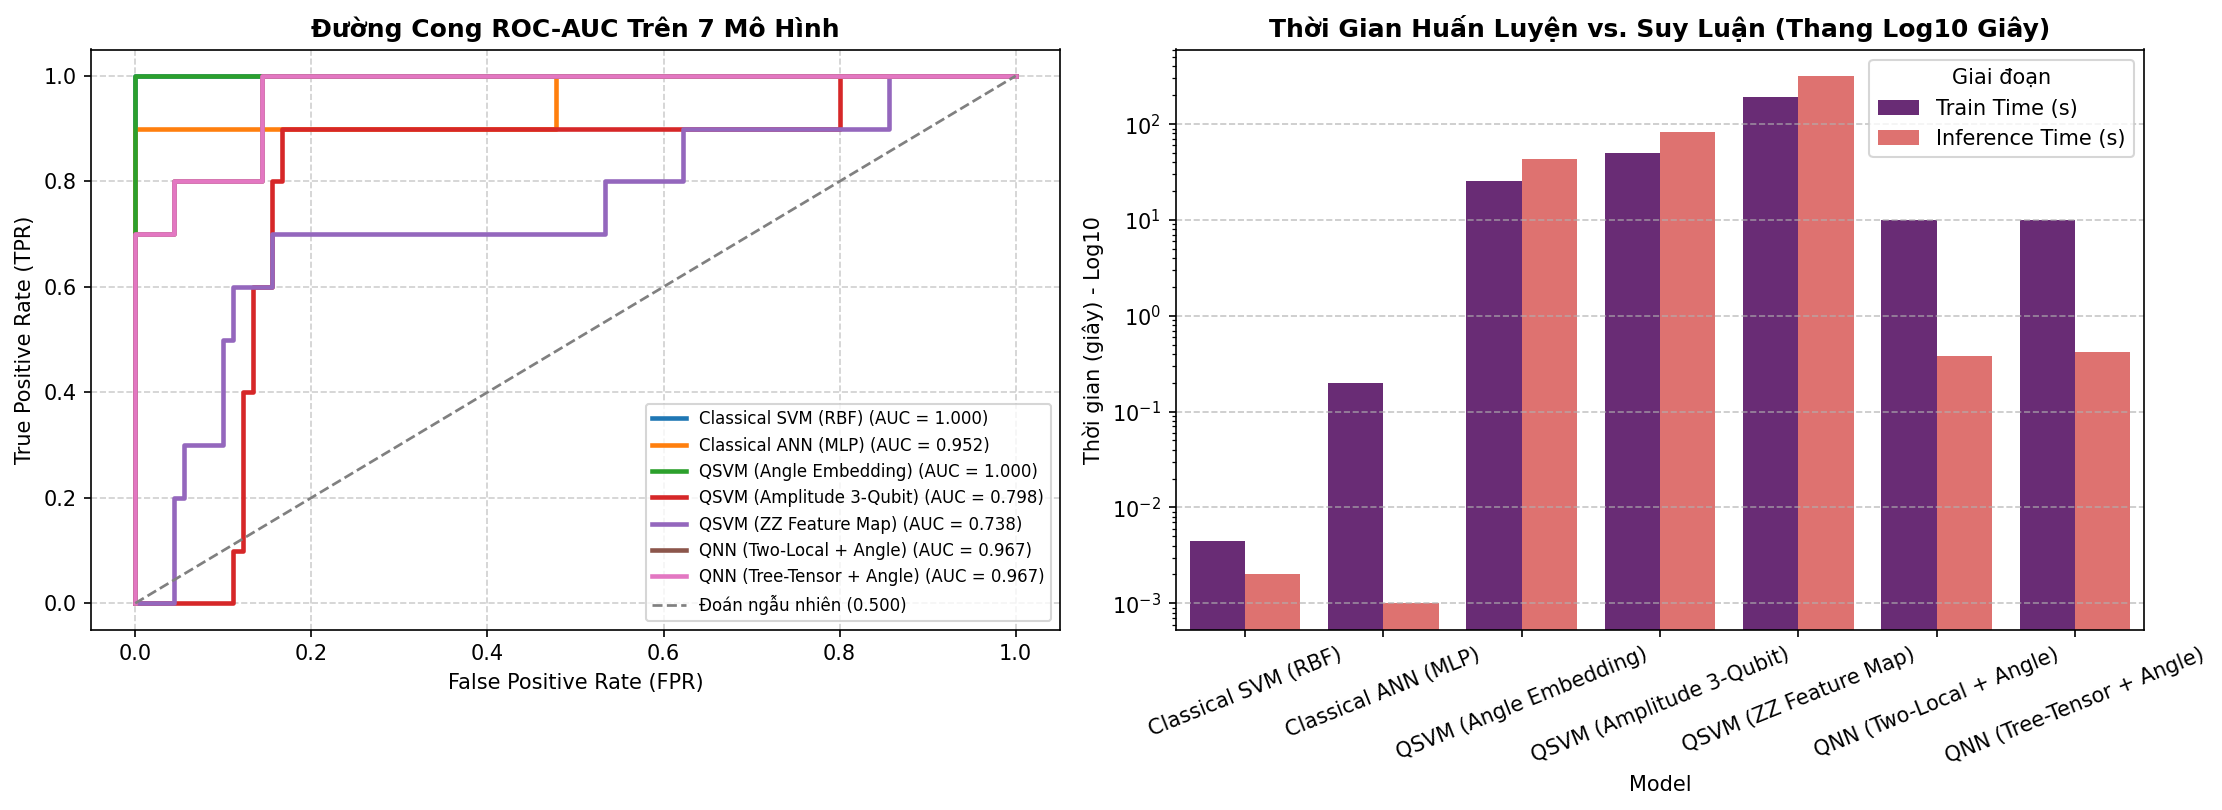

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=150)

palette_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
for idx, (m_name, (fpr, tpr, roc_auc)) in enumerate(roc_dict.items()):
    ax1.plot(fpr, tpr, lw=2.2, color=palette_colors[idx % len(palette_colors)],
             label=f"{m_name} (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], color='gray', lw=1.3, linestyle='--', label='Đoán ngẫu nhiên (0.500)')
ax1.set_title("Đường Cong ROC-AUC Trên 7 Mô Hình", fontweight="bold")
ax1.set_xlabel("False Positive Rate (FPR)")
ax1.set_ylabel("True Positive Rate (TPR)")
ax1.legend(loc="lower right", fontsize=8)
ax1.grid(True, linestyle="--", alpha=0.6)

df_time = df_eval.melt(
    id_vars=["Model", "Type"],
    value_vars=["Train Time (s)", "Inference Time (s)"],
    var_name="Giai đoạn", value_name="Thời gian (Giây)"
)
sns.barplot(data=df_time, x="Model", y="Thời gian (Giây)", hue="Giai đoạn", palette="magma", ax=ax2)
ax2.set_yscale("log")
ax2.set_title("Thời Gian Huấn Luyện vs. Suy Luận (Thang Log10 Giây)", fontweight="bold")
ax2.set_ylabel("Thời gian (giây) - Log10")
ax2.tick_params(axis='x', rotation=22)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

---
## BƯỚC 5: Đối Chiếu Với Bảng 12 Mô Hình Của Bài Báo Gốc & Kết Quả Mở Rộng Đa Lớp (`Multiclass 4-Class DDoS`)

In [6]:
paper_csv = os.path.join(RESULTS_DIR, "bang_tong_hop_benchmark_chinh_thuc_bai_bao.csv")
df_paper = pd.read_csv(paper_csv)
print("=" * 120)
print("BẢNG ĐỐI CHIẾU: TOÀN BỘ 12 CẤU HÌNH MÔ HÌNH TRONG BÀI BÁO GỐC (FULL 100K & SMALL 1K)")
print("=" * 120)
print(df_paper[["Mô hình", "Tập dữ liệu", "Số Qubit", "Độ chính xác (Acc)", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)", "F1 (Benign - Lớp 1)", "ROC-AUC", "Thời gian Huấn luyện (s)", "Thời gian Suy luận (s)"]].to_string(index=False))

mc_csv = os.path.join(RESULTS_DIR, "multiclass_benchmark_summary.csv")
df_mc = pd.read_csv(mc_csv)
print("\n" + "=" * 105)
print("BẢNG KẾT QUẢ MỞ RỘNG PHÂN LOẠI ĐA LỚP (MULTICLASS 4 LOẠI LƯU LƯỢNG: SYN, BENIGN, UDP, DNS)")
print("=" * 105)
print(df_mc.to_string(index=False))

BẢNG ĐỐI CHIẾU: TOÀN BỘ 12 CẤU HÌNH MÔ HÌNH TRONG BÀI BÁO GỐC (FULL 100K & SMALL 1K)
                                 Mô hình                  Tập dữ liệu  Số Qubit  Độ chính xác (Acc)  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  F1 (Benign - Lớp 1)  ROC-AUC  Thời gian Huấn luyện (s)  Thời gian Suy luận (s)
                     Classical SVM (RBF)  FULL (80k Train / 10k Test)         0              0.9926               0.97            1.00              0.98                 0.96   0.9954                      0.98                    0.13
          Classical ANN (MLP 8-8-16-8-1)  FULL (80k Train / 10k Test)         0              0.9941               0.97            0.99              0.98                 0.97   0.9988                     21.00                    0.39
                  QSVM (Angle Embedding) SMALL (800 Train / 100 Test)         8              0.9900               0.95            0.99              0.97                 0.95   0.9944                   1265.59        